Autor: Igor Jakus, 344874

Data: 14-10-2026


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(42)

def metrics(estimates, theta):
    # estimates: (samples, #estimators)
    # theta: (1,)
    obciazenie = estimates.mean(axis=0) - theta   # (#estimators,) - (1,) = (#estimators)
    wariancja = estimates.var(axis=0)             # (#estimators)
    mse = ((estimates - theta) ** 2).mean(axis=0) # (#estimators)
    return np.column_stack((obciazenie, wariancja, mse))  # (#estimators, 3)


def results(metric_values, names) -> None:
    """Wyświetla tabelę miar jakości estymatorów."""
    print(f"{'estymator':<22} {'obciazenie':>12} {'wariancja':>12} {'mse':>12} {'~=0':>12}")
    for name, row in zip(names, metric_values):
        sanity_check = row[2] - row[1] - row[0]**2
        print(f"{name:<22} {row[0]:12.5g} {row[1]:12.5g} {row[2]:12.5g} {sanity_check:12.5g}")


def boxes(ax, estimates, names, theta, title) -> None:
    # estimates: (samples, #estimators)
    """Rysuje wykres pudełkowy"""
    # boxplot daje nam pudelko dla kazdej kolumny czyli dla kazdego estymatora
    ax.boxplot(estimates, tick_labels=names, showfliers=False)  # ukrywamy outliery <=> dalej niz 1.5x IQR
    ax.axhline(theta, color="tab:red", linestyle=":")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=25)
    ax.set_ylabel("wartosc estymatora")

# Zadanie 1

## Teoria

$$
\operatorname{Bias}_\theta(\widehat{\theta})=\mathbb{E}_\theta[\widehat{\theta}]-\theta,
$$

$$
\operatorname{Var}_\theta(\widehat{\theta})=\mathbb{E}_\theta\!\left[(\widehat{\theta}-\mathbb{E}_\theta[\widehat{\theta}])^2\right],
$$

$$
\operatorname{MSE}_\theta(\widehat{\theta})=\mathbb{E}_\theta\!\left[(\widehat{\theta}-\theta)^2\right].
$$

Udowodniliśmy na wykładzie, że

$$
\operatorname{MSE}_\theta(\widehat{\theta})=\operatorname{Var}_\theta(\widehat{\theta})+\operatorname{Bias}_\theta(\widehat{\theta})^2.
$$


### Rozwiązanie

W estymatorzy 3-cim wybraliśmy wagi $w_i = \frac{i}{1 + \dots + n}$, tak żeby $\sum w_i = 1$.

Estymator 7-my zdefiniowaliśmy jako $\widehat{\theta_7} = \frac{\min x + \max x }{2}$, gdzie $x$ jest próbą.

W kolumnie "$\approx 0$" korzystamy z twierdzenia udowodnionego na wykładzie i sprawdzamy:

$$
\operatorname{MSE}_\theta(\widehat{\theta})-\operatorname{Var}_\theta(\widehat{\theta})-\operatorname{Bias}_\theta(\widehat{\theta})^2\approx 0.
$$

jako "sanity check".



n = 20, theta = 0, sigma = 1

estymator                obciazenie    wariancja          mse          ~=0
srednia                 -0.00075783     0.049792     0.049793   9.4699e-17
mediana                  -0.0029031     0.073487     0.073495    6.122e-17
wazona                   -0.0027337     0.065781     0.065789   -8.046e-17
wzor 4 (?)                  0.93418     0.023407       0.8961  -1.1102e-15
sr harmoniczna               60.583      3.6e+07   3.6004e+07  -1.1444e-07
sr pot rzedu 3           -0.0021545      0.68673      0.68673   3.5528e-15
sr min-max                0.0051465      0.14414      0.14417  -1.2301e-15

n = 50, theta = 0, sigma = 1

estymator                obciazenie    wariancja          mse          ~=0
srednia                  -0.0013733     0.019632     0.019633   3.7256e-17
mediana                  4.3185e-05     0.029858     0.029858   2.3433e-16
wazona                   -0.0018127     0.025904     0.025908   4.8457e-17
wzor 4 (?)                  0.97066   

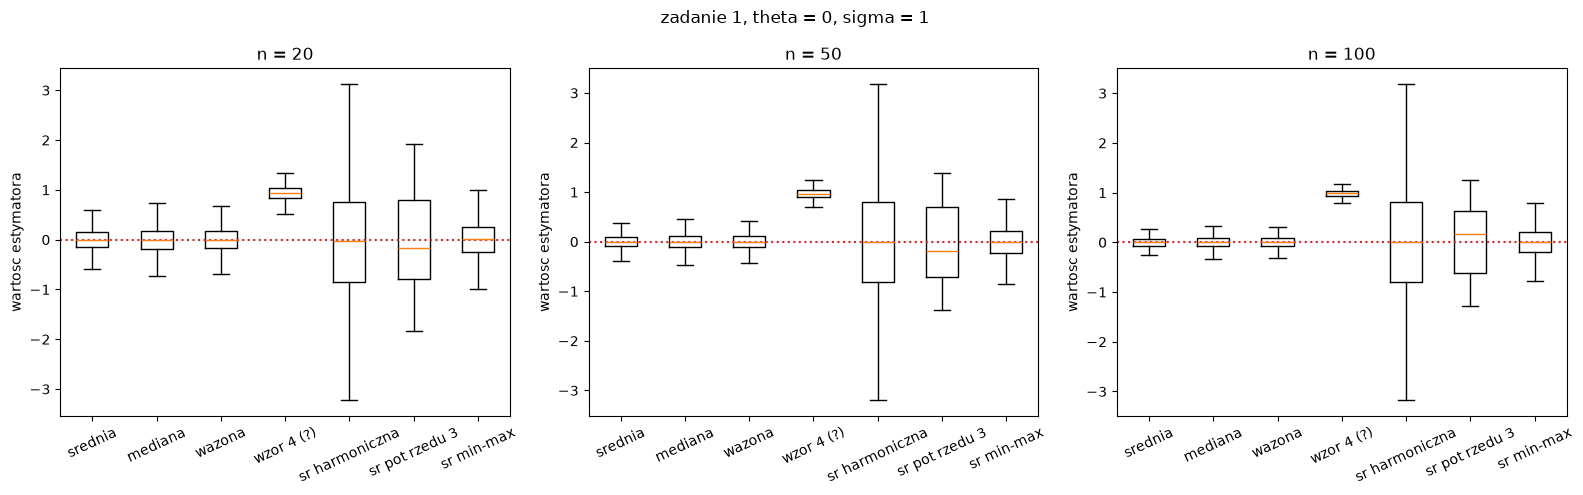


n = 20, theta = 0, sigma = 2

estymator                obciazenie    wariancja          mse          ~=0
srednia                  0.00065482      0.19546      0.19546   2.4317e-16
mediana                  -0.0021147      0.28572      0.28572   1.8661e-16
wazona                    0.0016707      0.25714      0.25715   3.3917e-16
wzor 4 (?)                   1.8643     0.093696       3.5692   2.1316e-14
sr harmoniczna              0.90652        39072        39073   1.0578e-10
sr pot rzedu 3            0.0034464       2.7283       2.7283   1.4204e-14
sr min-max               -0.0035882      0.57348      0.57349  -8.6459e-16

n = 50, theta = 0, sigma = 2

estymator                obciazenie    wariancja          mse          ~=0
srednia                 -0.00052739     0.080401     0.080401  -1.6156e-16
mediana                   0.0013416      0.12192      0.12192  -9.7633e-16
wazona                     0.001522      0.10669      0.10669   7.0891e-16
wzor 4 (?)                   1.9423   

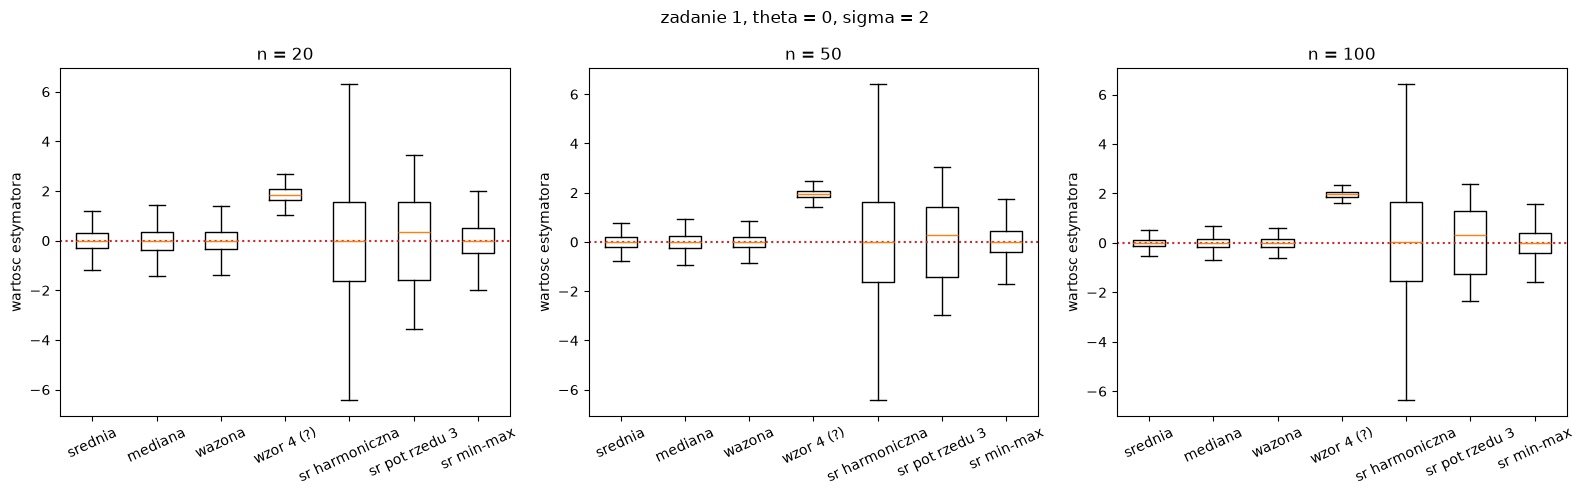


n = 20, theta = 4, sigma = 1

estymator                obciazenie    wariancja          mse          ~=0
srednia                  0.00035495     0.050389     0.050389  -3.6764e-16
mediana                  0.00082673     0.073321     0.073322  -3.7954e-16
wazona                   0.00081805     0.066105     0.066105    1.722e-16
wzor 4 (?)                  -3.0713     0.022963       9.4556   4.2633e-14
sr harmoniczna             -0.27612       0.1133      0.18954   8.7153e-15
sr pot rzedu 3              0.22294     0.049927     0.099629   3.2127e-15
sr min-max               -0.0027633      0.14037      0.14038  -4.0303e-16

n = 50, theta = 4, sigma = 1

estymator                obciazenie    wariancja          mse          ~=0
srednia                   -3.34e-05     0.020136     0.020136  -7.9725e-17
mediana                   0.0021326     0.030384     0.030388  -1.3079e-16
wazona                   0.00024603     0.026724     0.026724  -3.3596e-17
wzor 4 (?)                  -3.0283   

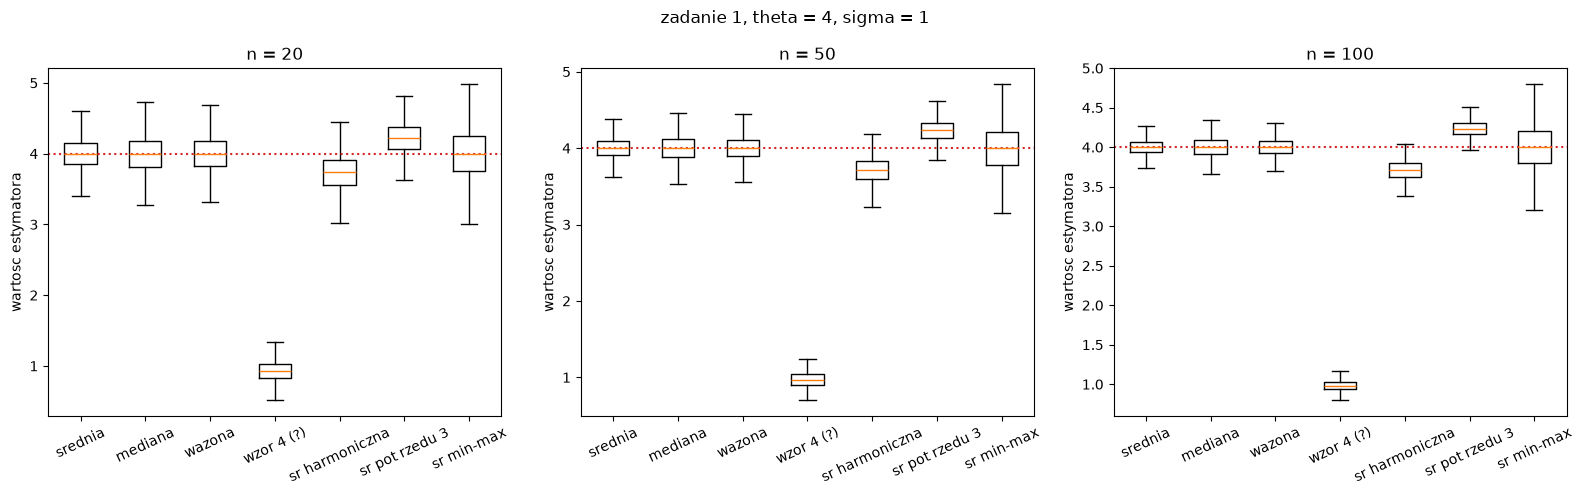


n = 20, theta = 4, sigma = 2

estymator                obciazenie    wariancja          mse          ~=0
srednia                  -0.0023877      0.20004      0.20005   4.5808e-16
mediana                  0.00074205      0.29003      0.29003  -7.3968e-16
wazona                   5.5254e-05      0.25794      0.25794   1.0283e-15
wzor 4 (?)                   -2.132     0.092691       4.6381  -2.3981e-14
sr harmoniczna              -3.6951        57301        57315   1.1063e-11
sr pot rzedu 3              0.77918      0.19963      0.80674  -6.2172e-15
sr min-max                -0.011667      0.57425      0.57439    3.456e-15

n = 50, theta = 4, sigma = 2

estymator                obciazenie    wariancja          mse          ~=0
srednia                 -0.00053217     0.079693     0.079693   7.5139e-17
mediana                   0.0034381      0.12059       0.1206  -4.2539e-16
wazona                   -0.0013072      0.10528      0.10529  -1.6415e-16
wzor 4 (?)                   -2.058   

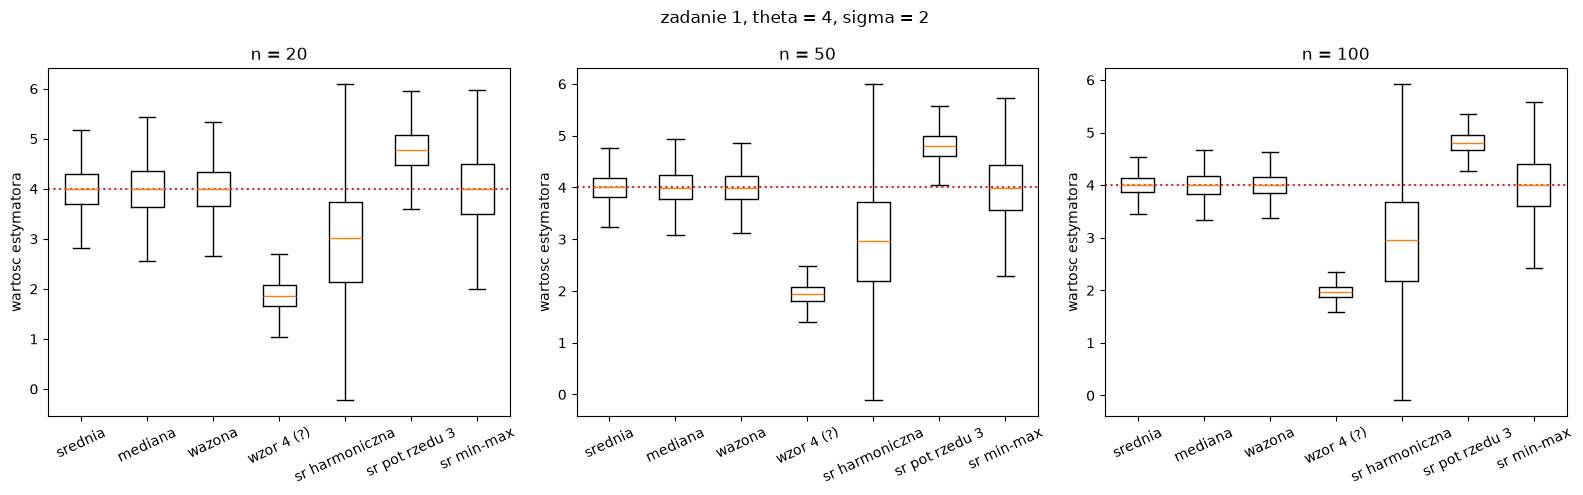

In [2]:
samples = 10000
cases = [(0, 1), (0, 2), (4, 1), (4, 2)]  # (theta, sigma)

# zadanie 1
names = ["srednia", "mediana", "wazona", "wzor 4 (?)", "sr harmoniczna", "sr pot rzedu 3", "sr min-max"]

for theta, sigma in cases:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, n in zip(axes, [20, 50, 100]):
        wagi = np.arange(1, n + 1, dtype=float)
        wagi /= wagi.sum()
        phi = norm.pdf(norm.ppf(np.linspace(0, 1, n + 1)))
        wagi_iv = phi[:-1] - phi[1:]

        x = rng.normal(theta, sigma, size=(samples, n))
        x_sorted = np.sort(x, axis=1)
        # 1
        srednia = x.mean(axis=1)
        # 2
        mediana = np.median(x, axis=1)
        # 3
        srednia_wazona = np.sum(x * wagi, axis=1)
        # 4
        estymator_4 = np.sum(x_sorted * wagi_iv, axis=1)
        # 5
        srednia_harmoniczna = n / np.sum(1 / x, axis=1)
        # 6
        srednia_pot_3_rzedu = np.cbrt(np.mean(x ** 3, axis=1))
        # 7
        srednia_min_max = (x_sorted[:, 0] + x_sorted[:, -1]) / 2

        estimates = np.column_stack([
            srednia, mediana, srednia_wazona, estymator_4,
            srednia_harmoniczna, srednia_pot_3_rzedu, srednia_min_max,
        ])
        print(f"\nn = {n}, theta = {theta}, sigma = {sigma}\n")
        metric_values = metrics(estimates, theta)
        results(metric_values, names)
        boxes(ax, estimates, names, theta, f"n = {n}")

    fig.suptitle(f"zadanie 1, theta = {theta}, sigma = {sigma}")
    fig.tight_layout()
    plt.show()


### Wnioski

- **Średnia:** wraz ze wzrostem $n$ jej rozrzut maleje; dla rozkładu normalnego jest nieobciążona, a jej wariancja wynosi $\sigma^2/n$.
- **Mediana:** jej rozrzut również maleje wraz ze wzrostem $n$; w rozkładzie normalnym jest nieobciążona dla parametru położenia $\theta$.
- **Średnia ważona:** wagi sumują się do 1, więc estymator jest nieobciążony; wraz ze wzrostem $n$ jego wariancja maleje, choć jest większa niż wariancja zwykłej średniej.
- **Estymator 4:** wagi zdefiniowane w kodzie sumują się do zera, więc estymator nie przesuwa się razem z $\theta$ i nie jest właściwym estymatorem parametru położenia.
- **Średnia harmoniczna:** jest niestabilna, gdy obserwacje są bliskie zeru, a przy próbie zawierającej wartości różnych znaków może być myląca; nie jest odpowiednim estymatorem położenia w rozważanych przypadkach.
- **Średnia potęgowa rzędu 3:** na ogół jest obciążona dla $\theta$, ponieważ sześcian obserwacji zależy zarówno od $\theta$, jak i od $\sigma$; zwiększenie $n$ nie usuwa tego obciążenia.
- **Średnia min-max:** dla rozkładu normalnego jej rozrzut maleje wraz ze wzrostem $n$, ale krańcowe obserwacje czynią ją wrażliwą na wartości skrajne.

Większe $\sigma$ zwiększa rozrzut wyników. Wnioski te dotyczą rozkładu normalnego i badanych wartości parametrów.